# 03 — Exploratory Data Analysis

Data: `data/processed/taxis_clean.csv` (output of `02_data_cleaning`).
Charts are also saved to `report/figures/` for the final report.

In [1]:
# ==========================================
# 1. IMPORT LIBRARIES & CHART STYLE
# ==========================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.max_columns", None)

# Consistent palette (validated for colour-blind separation)
BLUE, ORANGE = "#2a78d6", "#eb6834"
TAXI_COLORS = {"yellow": "#eda100", "green": "#008300"}
TEXT, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": MUTED,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "text.color": TEXT,
    "text.parse_math": False,  # so "$" in labels is shown, not treated as math
})

FIG_DIR = "../dashboard/figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight", dpi=150)

usd = mtick.StrMethodFormatter("${x:,.0f}")

In [2]:
# ==========================================
# 2. LOAD CLEAN DATA
# ==========================================

df = pd.read_csv("../data/processed/taxis_clean.csv", parse_dates=["pickup", "dropoff"])

# CSV does not keep dtypes, so restore them
categorical_cols = ["color", "payment", "pickup_zone", "dropoff_zone",
                    "pickup_borough", "dropoff_borough"]
df[categorical_cols] = df[categorical_cols].astype("category")
df["passengers"] = df["passengers"].astype("Int64")
df["pickup_day"] = pd.Categorical(
    df["pickup_day"],
    categories=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
    ordered=True,
)

print(f"Shape: {df.shape}")

Shape: (6371, 22)


---
# Part 1 — How does the taxi company generate revenue?

**Revenue definition:** `total` = the full amount the passenger paid for the trip (fare + tip + tolls + surcharges/taxes).
`fare` = the metered part only. Both are used below, and the notebook says which one each time.

## 1.1 Total recorded revenue
What is the total, and what is it made of?

In [3]:
# ==========================================
# 3. TOTAL REVENUE & COMPOSITION
# ==========================================

# Surcharges/taxes are not a separate column; they are what's left of total
df["surcharges"] = df["total"] - df["fare"] - df["tip"] - df["tolls"]

components = df[["fare", "surcharges", "tip", "tolls"]].sum().sort_values()
composition = pd.DataFrame({
    "amount": components.round(2),
    "share_%": (components / df["total"].sum() * 100).round(1),
})

print(f"Total recorded revenue: ${df['total'].sum():,.2f} across {len(df):,} trips")
composition.sort_values("amount", ascending=False)

Total recorded revenue: $117,554.60 across 6,371 trips


,amount,share_%
fare,82929.11,70.5
surcharges,19998.40,17.0
tip,12567.13,10.7
tolls,2059.96,1.8


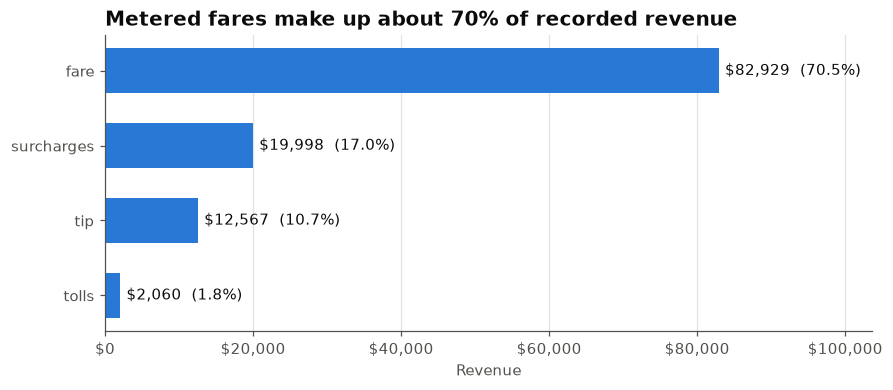

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5))
bars = ax.barh(composition.index, composition["amount"], color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"${a:,.0f}  ({s}%)" for a, s in composition.values], padding=4, color=TEXT)

ax.set_title("Metered fares make up about 70% of recorded revenue")
ax.set_xlabel("Revenue")
ax.xaxis.set_major_formatter(usd)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, composition["amount"].max() * 1.25)

save_fig(fig, "01_revenue_composition")
plt.show()

**Insight:** Total recorded revenue is **$117,555** from 6,371 trips.
- **Fares: $82,929 (70.5%)**. This is the core of the business.
- **Surcharges/taxes: $19,998 (17.0%)**
- **Tips: $12,567 (10.7%)**. Tips mostly go to drivers, and cash tips aren't recorded, so the real figure is higher.
- **Tolls: $2,060 (1.8%)**. These are passed through to the toll operator, so they aren't real income.

So the company earns its money mainly from metered fares. Tips and tolls make the "total" look bigger than what the company actually keeps.

## 1.2 Average revenue per trip & revenue distribution

In [5]:
# ==========================================
# 4. REVENUE PER TRIP
# ==========================================

df["total"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(2)

count    6371.00
mean       18.45
std        13.43
min         1.30
25%        10.80
50%        14.16
75%        20.30
90%        33.30
99%        73.27
max       174.82
Name: total, dtype: float64

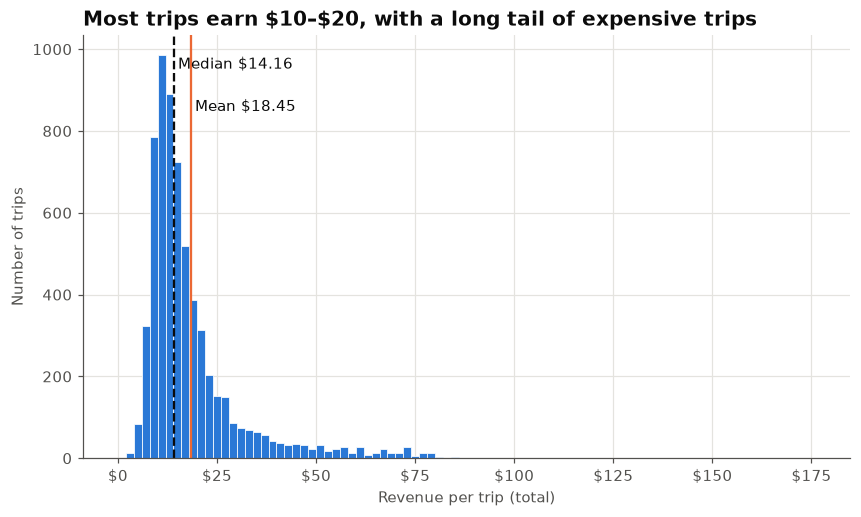

In [6]:
mean_rev, median_rev = df["total"].mean(), df["total"].median()

fig, ax = plt.subplots()
ax.hist(df["total"], bins=np.arange(0, df["total"].max() + 2, 2), color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(median_rev, color=TEXT, linewidth=1.5, linestyle="--")
ax.axvline(mean_rev, color=ORANGE, linewidth=1.5)
ax.text(median_rev + 1, ax.get_ylim()[1] * 0.92, f"Median ${median_rev:.2f}", color=TEXT)
ax.text(mean_rev + 1, ax.get_ylim()[1] * 0.82, f"Mean ${mean_rev:.2f}", color=TEXT)

ax.set_title("Most trips earn $10–$20, with a long tail of expensive trips")
ax.set_xlabel("Revenue per trip (total)")
ax.set_ylabel("Number of trips")
ax.xaxis.set_major_formatter(usd)

save_fig(fig, "02_revenue_distribution")
plt.show()

**Insight:**
- **Average revenue per trip is $18.45**, but the **median is only $14.16**. Half of all trips bring in less than $14.16.
- The distribution is **right-skewed**. A small number of expensive trips pull the mean above the median, so the median describes a "typical" trip better.
- Half of all trips fall between **$10.80 and $20.30**, and 99% are below about $70.

## 1.3 Is revenue concentrated among short or long trips?

In [ ]:
# ==========================================
# 5. REVENUE BY TRIP DISTANCE
# ==========================================

bins = [0, 2, 5, 10, np.inf]
labels = ["Under 2 mi", "2-5 mi", "5-10 mi", "10+ mi"]
df["distance_band"] = pd.cut(df["distance"], bins=bins, labels=labels)

by_band = df.groupby("distance_band", observed=True).agg(
    trips=("total", "size"),
    revenue=("total", "sum"),
    avg_revenue=("total", "mean"),
)
by_band["trip_share_%"] = by_band["trips"] / by_band["trips"].sum() * 100
by_band["revenue_share_%"] = by_band["revenue"] / by_band["revenue"].sum() * 100
by_band.round(1)

,trips,revenue,avg_revenue,trip_share_%,revenue_share_%
distance_band,,,,,
Under 2 mi,3746,43923.0,11.7,58.8,37.4
2–5 mi,1667,32265.4,19.4,26.2,27.4
5–10 mi,565,18370.6,32.5,8.9,15.6
10+ mi,393,22995.6,58.5,6.2,19.6


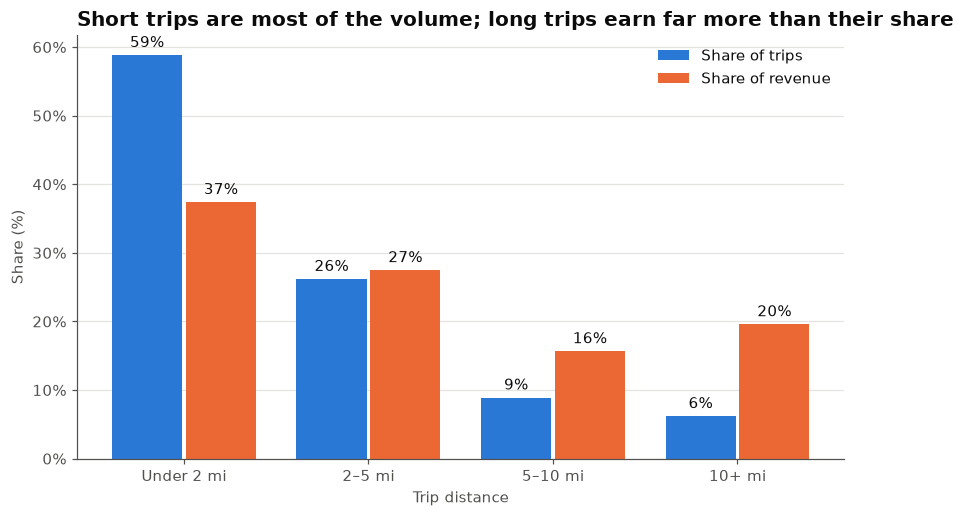

Top 10% most expensive trips generate 27.9% of revenue


In [8]:
x = np.arange(len(by_band))
w = 0.38

fig, ax = plt.subplots()
b1 = ax.bar(x - w / 2 - 0.01, by_band["trip_share_%"], w, color=BLUE, label="Share of trips")
b2 = ax.bar(x + w / 2 + 0.01, by_band["revenue_share_%"], w, color=ORANGE, label="Share of revenue")
ax.bar_label(b1, fmt="%.0f%%", padding=3, color=TEXT)
ax.bar_label(b2, fmt="%.0f%%", padding=3, color=TEXT)

ax.set_title("Short trips are most of the volume; long trips earn far more than their share")
ax.set_xticks(x, by_band.index)
ax.set_xlabel("Trip distance")
ax.set_ylabel("Share (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)

save_fig(fig, "03_revenue_by_distance")
plt.show()

top10_share = df["total"].nlargest(int(len(df) * 0.10)).sum() / df["total"].sum()
print(f"Top 10% most expensive trips generate {top10_share:.1%} of revenue")

**Insight: revenue is spread across both, but long trips are much more valuable per trip.**
- **Short trips (under 2 mi)** are **59% of trips** but only **37% of revenue**, at about $11.70 per trip.
- **Long trips (10+ mi)** are just **6% of trips** but bring in **20% of revenue**, at about $58.50 per trip, 5× a short trip.
- The **top 10% of trips by value generate 28% of revenue**.

Short trips are the volume base. Long trips, many of them airport runs, add a lot of revenue for only a few rides.

## 1.4 Does longer distance generally mean higher fare?

In [9]:
# ==========================================
# 6. FARE VS DISTANCE
# ==========================================

slope, intercept = np.polyfit(df["distance"], df["fare"], 1)
pearson_r = df["distance"].corr(df["fare"])
spearman_r = df["distance"].corr(df["fare"], method="spearman")

print(f"Fare ≈ ${intercept:.2f} + ${slope:.2f} × miles")
print(f"Pearson r = {pearson_r:.3f}  (R² = {pearson_r**2:.3f})")
print(f"Spearman ρ = {spearman_r:.3f}")

Fare ≈ $4.45 + $2.81 × miles
Pearson r = 0.959  (R² = 0.920)
Spearman ρ = 0.944


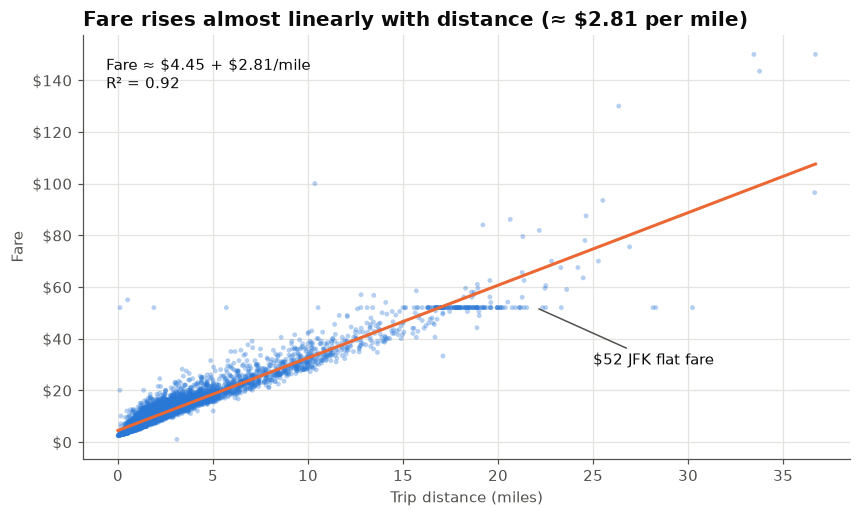

In [10]:
fig, ax = plt.subplots()
ax.scatter(df["distance"], df["fare"], s=10, alpha=0.35, color=BLUE, edgecolors="none")

xs = np.linspace(0, df["distance"].max(), 100)
ax.plot(xs, intercept + slope * xs, color=ORANGE, linewidth=2)
ax.text(0.03, 0.95, f"Fare ≈ ${intercept:.2f} + ${slope:.2f}/mile\nR² = {pearson_r**2:.2f}",
        transform=ax.transAxes, va="top", color=TEXT)
ax.annotate("$52 JFK flat fare", xy=(22, 52), xytext=(25, 30), color=TEXT,
            arrowprops=dict(arrowstyle="-", color=MUTED))

ax.set_title("Fare rises almost linearly with distance (≈ $2.81 per mile)")
ax.set_xlabel("Trip distance (miles)")
ax.set_ylabel("Fare")
ax.yaxis.set_major_formatter(usd)

save_fig(fig, "04_fare_vs_distance")
plt.show()

**Insight: yes, distance explains most of the fare.**
- Correlation is **r = 0.96 (R² = 0.92)**. Distance alone explains about 92% of the variation in fares.
- Rule of thumb: **fare ≈ $4.45 + $2.81 per mile**.
- The points that sit off the line are mostly:
  - **Flat-rate trips**: a horizontal band at exactly **$52**, the fixed JFK–Manhattan fare. There are 126 such trips, and 114 of them involve JFK. Their fare doesn't change with distance, which is why they fall below the line beyond about 17 mi.
  - **Slow trips**: points above the line, where time in traffic adds to the meter.
  - **Very short trips with a high fare**: see 1.5.

## 1.5 Are there unusually expensive trips?
Two kinds of "expensive":
1. **High total**: expensive in absolute terms
2. **High fare per mile**: expensive for the distance travelled. These are more suspicious.

In [11]:
# ==========================================
# 7. UNUSUALLY EXPENSIVE TRIPS
# ==========================================

q1, q3 = df["total"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
high_total = df[df["total"] > upper_fence]

is_airport = (df["pickup_zone"].str.contains("Airport", na=False)
              | df["dropoff_zone"].str.contains("Airport", na=False))

print(f"IQR upper fence for total: ${upper_fence:.2f}")
print(f"Trips above it: {len(high_total)} ({len(high_total) / len(df):.1%}), "
      f"earning {high_total['total'].sum() / df['total'].sum():.1%} of revenue")
print(f"Of these, {is_airport[high_total.index].mean():.0%} start or end at an airport, "
      f"average distance {high_total['distance'].mean():.1f} mi")

cols = ["pickup", "distance", "duration_min", "fare", "tip", "tolls", "total",
        "payment", "pickup_zone", "dropoff_zone"]
df.nlargest(10, "total")[cols]

IQR upper fence for total: $34.55
Trips above it: 585 (9.2%), earning 26.4% of revenue
Of these, 57% start or end at an airport, average distance 12.9 mi


,pickup,distance,duration_min,fare,tip,tolls,total,payment,pickup_zone,dropoff_zone
5328,2019-03-17 16:59:17,36.70,64.850000,150.00,0.00,24.02,174.82,cash,JFK Airport,JFK Airport
5606,2019-03-19 14:21:35,33.46,89.883333,150.00,0.00,18.90,169.70,cash,East Flushing,Unknown
4023,2019-03-13 14:05:19,33.76,55.950000,143.50,0.00,0.00,144.30,cash,LaGuardia Airport,Unknown
2217,2019-03-11 10:17:31,26.35,46.400000,130.00,0.00,5.76,136.56,cash,East Harlem North,Unknown
4782,2019-03-08 11:25:08,10.36,25.366667,100.00,20.56,0.00,123.36,credit card,TriBeCa/Civic Center,Unknown
4191,2019-03-08 20:07:54,36.66,62.100000,96.50,10.00,5.76,113.56,credit card,JFK Airport,Unknown
3476,2019-03-11 17:18:03,24.63,69.750000,87.50,17.86,0.00,107.16,credit card,LaGuardia Airport,Unknown
4190,2019-03-29 17:32:20,26.92,81.533333,75.50,23.19,0.00,100.49,credit card,JFK Airport,Cobble Hill
5527,2019-03-07 00:28:57,25.51,93.966667,93.50,0.00,0.00,94.80,credit card,Sunset Park West,Saint Albans
5780,2019-03-05 10:34:36,20.64,69.416667,86.14,0.00,5.76,92.40,credit card,Coney Island,Upper East Side North


In [12]:
df["fare_per_mile"] = df["fare"] / df["distance"]

# Typical NYC fare is ~$2.50–$7/mile; >$50/mile means a large fare for almost no distance
suspicious = df[df["fare_per_mile"] > 50]

print(f"Median fare per mile: ${df['fare_per_mile'].median():.2f}")
print(f"Trips charging more than $50/mile: {len(suspicious)}")
suspicious.sort_values("fare_per_mile", ascending=False)[
    ["distance", "duration_min", "fare", "total", "fare_per_mile", "pickup_zone", "dropoff_zone"]
].round(2)

Median fare per mile: $5.42
Trips charging more than $50/mile: 10


,distance,duration_min,fare,total,fare_per_mile,pickup_zone,dropoff_zone
2136,0.11,0.45,52.0,60.30,472.73,Lincoln Square West,Clinton West
4329,0.01,0.22,2.5,4.30,250.00,JFK Airport,JFK Airport
4531,0.10,0.15,20.0,20.80,200.00,Long Island City/Hunters Point,Long Island City/Hunters Point
455,0.02,0.23,2.5,6.30,125.00,Meatpacking/West Village West,Meatpacking/West Village West
4803,0.02,0.07,2.5,3.30,125.00,Sutton Place/Turtle Bay North,Sutton Place/Turtle Bay North
5453,0.02,0.22,2.5,3.30,125.00,Bayside,Bayside
6254,0.51,4.67,55.0,55.00,107.84,Maspeth,Ridgewood
733,0.03,0.07,2.5,3.80,83.33,Upper East Side South,Unknown
4099,0.04,0.15,2.5,3.80,62.50,Unknown,Unknown
5878,0.16,0.73,10.0,12.96,62.50,Murray Hill-Queens,Murray Hill-Queens


**Insight:**
*High-value trips are mostly real:*
- **585 trips (9.2%)** are above the outlier threshold of $34.55, and together they earn **26.4% of revenue**.
- **57% of them start or end at an airport**, and they average **12.9 mi**. These are genuine long trips, not errors, which is why the cleaning step **flagged** them instead of removing them.
- The top trips (up to $174.82) are 25–37 mi airport and out-of-city rides with tolls. The fares look plausible.
- Possible exception: a **JFK→JFK trip at $174.82**, the most expensive in the data. This is likely a negotiated or out-of-zone fare (the dropoff zone may be wrong) and worth checking.

*High fare per mile shows a few likely errors:*
- 10 trips charge more than $50/mile. **7 of them are just the $2.50 minimum fare** on a trip of almost zero distance, so they're cheap, not expensive.
- **3 trips are genuinely suspicious**: **$52 for 0.11 mi in 27 seconds**, **$20 for 0.10 mi in 9 seconds**, and **$55 for 0.51 mi**. These look like flat fares entered on trips that barely moved, or a broken meter.
- They make up only about $127 in revenue, so they don't affect the totals. They should still be excluded from any per-mile pricing analysis.

## 1.6 Does one taxi category generate more revenue?

In [13]:
# ==========================================
# 8. REVENUE BY TAXI COLOR
# ==========================================

by_color = df.groupby("color", observed=True).agg(
    trips=("total", "size"),
    revenue=("total", "sum"),
    avg_revenue=("total", "mean"),
    median_revenue=("total", "median"),
    avg_distance=("distance", "mean"),
    avg_tip=("tip", "mean"),
)
by_color["revenue_share_%"] = by_color["revenue"] / by_color["revenue"].sum() * 100
by_color = by_color.loc[["yellow", "green"]]
by_color.round(2)

,trips,revenue,avg_revenue,median_revenue,avg_distance,avg_tip,revenue_share_%
color,,,,,,,
yellow,5414,101658.5,18.78,14.3,2.97,2.18,86.48
green,957,15896.1,16.61,11.8,3.48,0.82,13.52


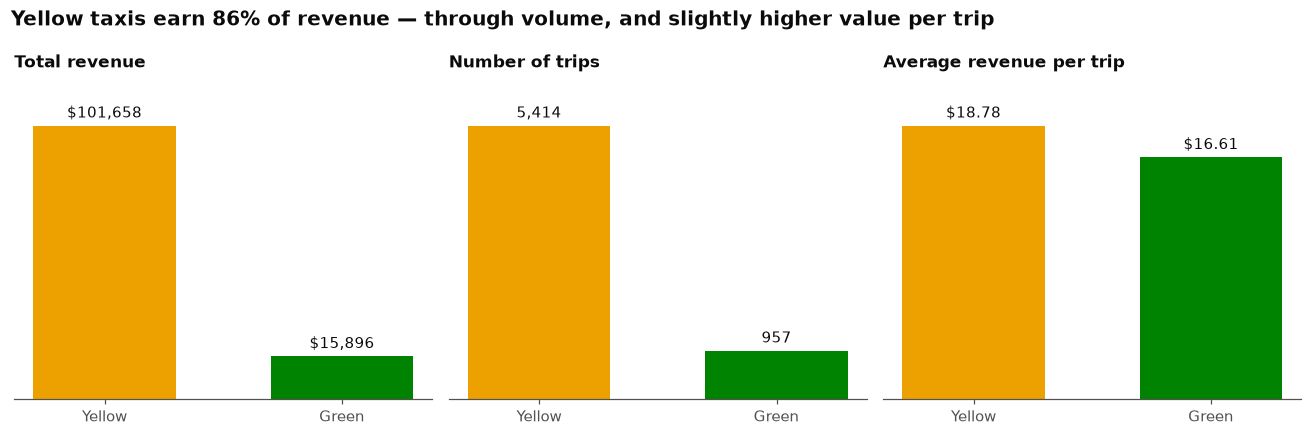

In [14]:
metrics = [
    ("revenue", "Total revenue", "${:,.0f}"),
    ("trips", "Number of trips", "{:,.0f}"),
    ("avg_revenue", "Average revenue per trip", "${:.2f}"),
]
colors = [TAXI_COLORS[c] for c in by_color.index]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (col, title, fmt) in zip(axes, metrics):
    bars = ax.bar(by_color.index.str.title(), by_color[col], color=colors, width=0.6)
    ax.bar_label(bars, labels=[fmt.format(v) for v in by_color[col]], padding=3, color=TEXT)
    ax.set_title(title, fontsize=11)
    ax.set_ylim(0, by_color[col].max() * 1.18)
    ax.yaxis.set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.grid(False)

fig.suptitle("Yellow taxis earn 86% of revenue — through volume, and slightly higher value per trip",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()

save_fig(fig, "05_revenue_by_color")
plt.show()

**Insight: yes, yellow taxis dominate.**
- **Yellow: $101,659 (86% of revenue)** from 5,414 trips.
- **Green: $15,896 (14%)** from 957 trips.
- Most of the gap comes from **volume**: yellow has 5.7× as many trips.
- Yellow also earns more per trip, **$18.78 vs $16.61 on average** (medians $14.30 vs $11.80), even though green trips are slightly *longer* (3.5 vs 3.0 mi).
- **Tips explain most of the per-trip gap**: average recorded tip is **$2.18 for yellow vs $0.82 for green**. Green cabs mainly serve the outer boroughs, where cash payment is more common, and cash tips aren't recorded. Part of the gap is likely missing data, not lower spending.

## Part 1 — Summary: how the company generates revenue

| Question | Answer |
|---|---|
| Total recorded revenue | **$117,555** from 6,371 trips; 70.5% from metered fares |
| Average revenue per trip | **$18.45** mean, **$14.16** median |
| Revenue distribution | Right-skewed: most trips earn $10–$20, with a long tail up to $175 |
| Short vs long trips | Short trips (<2 mi) = 59% of trips but 37% of revenue; long trips (10+ mi) = 6% of trips but 20% of revenue |
| Distance vs fare | Strong linear link: r = 0.96, ≈ $2.81 per mile |
| Unusually expensive trips | 9.2% of trips are high-value outliers (26% of revenue), mostly real airport/long trips; 3 near-zero-distance trips with $20–$55 fares are likely data errors |
| Taxi category | Yellow = 86% of revenue, mainly from volume, plus a higher average per trip |

**Business takeaway:** revenue comes from **many short Manhattan trips (the volume base)** plus **a small number of long and airport trips that bring in a lot per ride**. Distance is the main driver of what each trip earns.

---
# Part 2 — When do customers need taxis the most?

**Note on the data:** trips cover **March 2019** (plus 1 trip just before midnight on Feb 28). This dataset is a *sample*, so the counts show **relative** demand, not the true size of the NYC taxi market.
March 2019 has **5** Fridays, Saturdays and Sundays but only **4** of every other weekday. Day-of-week comparisons therefore use **trips per calendar day**, not raw counts.

## 2.1 Trips, revenue and average trip value by hour

In [15]:
# ==========================================
# 9. DEMAND BY HOUR
# ==========================================

by_hour = df.groupby("pickup_hour").agg(
    trips=("total", "size"),
    revenue=("total", "sum"),
    avg_revenue=("total", "mean"),
    avg_distance=("distance", "mean"),
)
by_hour["revenue_share_%"] = by_hour["revenue"] / by_hour["revenue"].sum() * 100

print(f"Busiest hour:             {by_hour['trips'].idxmax()}:00 ({by_hour['trips'].max()} trips)")
print(f"Highest-revenue hour:     {by_hour['revenue'].idxmax()}:00 (${by_hour['revenue'].max():,.0f})")
print(f"Highest avg trip value:   {by_hour['avg_revenue'].idxmax()}:00 (${by_hour['avg_revenue'].max():.2f})")
print(f"Quietest hour:            {by_hour['trips'].idxmin()}:00 ({by_hour['trips'].min()} trips)")
print(f"\nCorrelation (trips vs avg trip value, by hour): {by_hour['trips'].corr(by_hour['avg_revenue']):.2f}")

by_hour.round(2)

Busiest hour:             18:00 (416 trips)
Highest-revenue hour:     18:00 ($7,510)
Highest avg trip value:   5:00 ($23.67)
Quietest hour:            5:00 (51 trips)

Correlation (trips vs avg trip value, by hour): -0.31


,trips,revenue,avg_revenue,avg_distance,revenue_share_%
pickup_hour,,,,,
0,203,3950.25,19.46,3.66,3.36
1,110,1928.26,17.53,3.20,1.64
2,100,1716.83,17.17,3.23,1.46
3,66,1163.00,17.62,3.36,0.99
4,56,1249.10,22.31,4.50,1.06
5,51,1207.33,23.67,5.13,1.03
6,136,2366.77,17.40,3.46,2.01
7,217,4002.92,18.45,3.37,3.41
8,313,5329.13,17.03,2.63,4.53


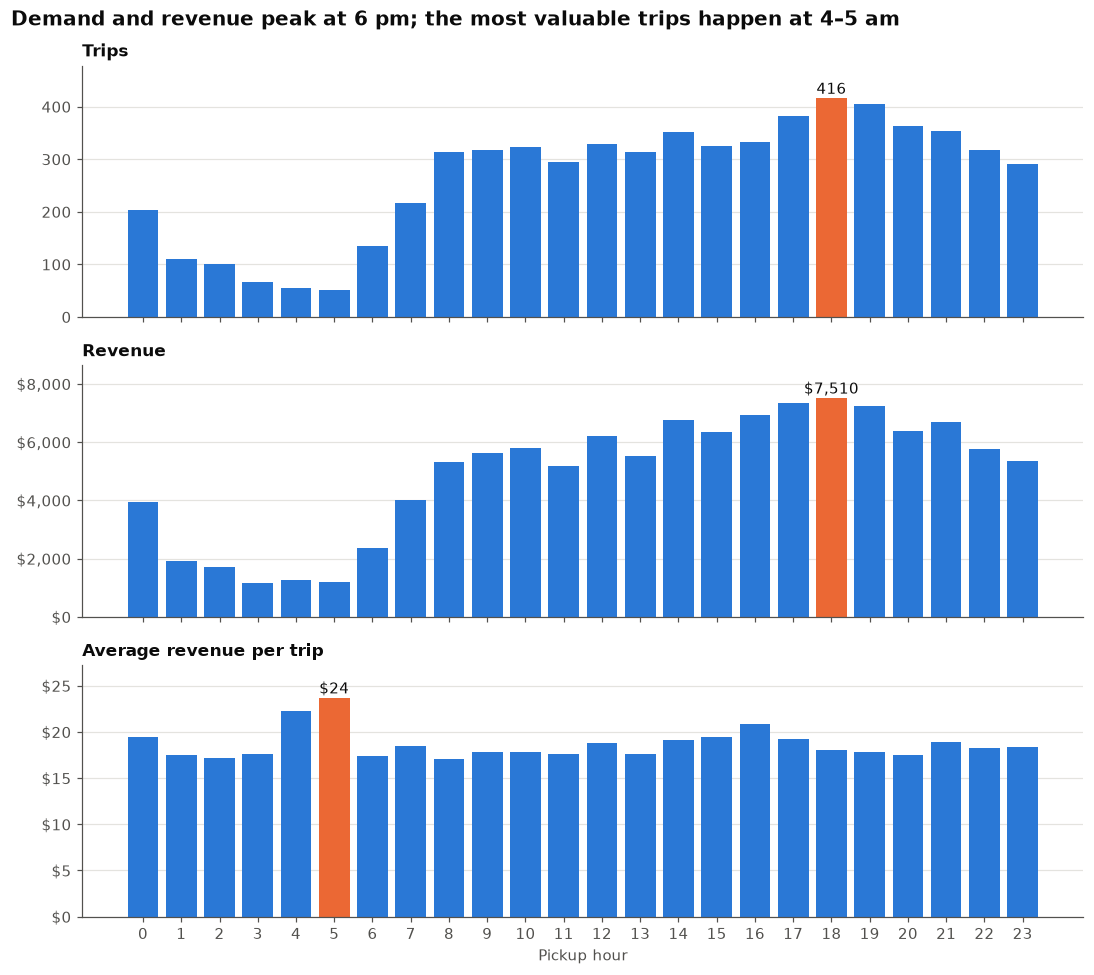

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
hours = by_hour.index

panels = [
    ("trips", "Trips", "{:,.0f}"),
    ("revenue", "Revenue", "${:,.0f}"),
    ("avg_revenue", "Average revenue per trip", "${:.0f}"),
]
for ax, (col, label, fmt) in zip(axes, panels):
    ax.bar(hours, by_hour[col], color=BLUE, width=0.8)
    top = by_hour[col].idxmax()
    ax.bar(top, by_hour.loc[top, col], color=ORANGE, width=0.8)  # highlight the peak
    ax.annotate(fmt.format(by_hour.loc[top, col]), (top, by_hour.loc[top, col]),
                xytext=(0, 3), textcoords="offset points", ha="center", color=TEXT)
    ax.set_title(label, fontsize=11)
    ax.set_ylim(0, by_hour[col].max() * 1.15)
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _, f=fmt: f.format(v)))

axes[-1].set_xticks(range(0, 24))
axes[-1].set_xlabel("Pickup hour")
fig.suptitle("Demand and revenue peak at 6 pm; the most valuable trips happen at 4–5 am",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()

save_fig(fig, "06_demand_by_hour")
plt.show()

**Insight:**
- **Busiest hour: 6 pm (18:00)** with 416 trips. Demand stays high from **5 pm to 9 pm** (350–416 trips per hour).
- **Highest-revenue hours: 6 pm ($7,510), 5 pm ($7,345), 7 pm ($7,224)**. The evening peak brings in the most money.
- **Low demand: 1 am to 6 am**, bottoming out at **5 am (51 trips)**, roughly 1/8 of the 6 pm peak.
- **Busy hours are *not* the most valuable per trip.** The highest average trip values are at **5 am ($23.67)** and **4 am ($22.31)**. Those trips are longer (4.5–5.1 mi on average, often to the airports). Across the 24 hours, trip count and average trip value are slightly **negatively** correlated (r = −0.31).
- So the evening peak earns the most in total **through volume**, while early-morning trips are few but valuable.

## 2.2 Trips by day of the week

In [17]:
# ==========================================
# 10. DEMAND BY DAY OF WEEK
# ==========================================

march = df[df["pickup"] >= "2019-03-01"]
calendar = pd.Series(pd.date_range("2019-03-01", "2019-03-31").day_name()).value_counts()

by_day = march.groupby("pickup_day", observed=True).agg(
    trips=("total", "size"),
    revenue=("total", "sum"),
    avg_revenue=("total", "mean"),
)
by_day["days_in_march"] = calendar.reindex(by_day.index).values
by_day["trips_per_day"] = by_day["trips"] / by_day["days_in_march"]
by_day["revenue_per_day"] = by_day["revenue"] / by_day["days_in_march"]
by_day.round(2)

,trips,revenue,avg_revenue,days_in_march,trips_per_day,revenue_per_day
pickup_day,,,,,,
Monday,705,13416.76,19.03,4,176.25,3354.19
Tuesday,814,15189.49,18.66,4,203.50,3797.37
Wednesday,956,18409.89,19.26,4,239.00,4602.47
Thursday,898,16965.40,18.89,4,224.50,4241.35
Friday,1102,20409.19,18.52,5,220.40,4081.84
Saturday,1031,17970.66,17.43,5,206.20,3594.13
Sunday,864,15186.91,17.58,5,172.80,3037.38


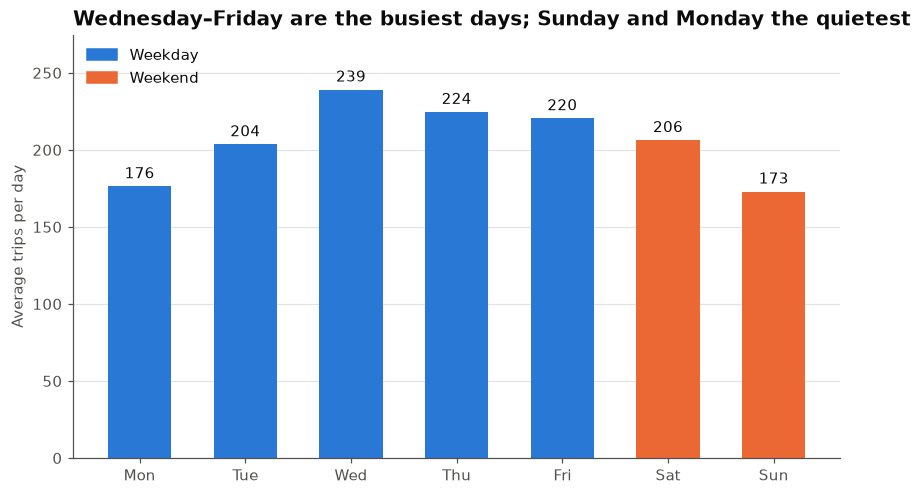

In [18]:
fig, ax = plt.subplots()
colors = [ORANGE if d in ("Saturday", "Sunday") else BLUE for d in by_day.index]
bars = ax.bar(by_day.index.str[:3], by_day["trips_per_day"], color=colors, width=0.6)
ax.bar_label(bars, fmt="%.0f", padding=3, color=TEXT)

ax.set_title("Wednesday–Friday are the busiest days; Sunday and Monday the quietest")
ax.set_ylabel("Average trips per day")
ax.set_ylim(0, by_day["trips_per_day"].max() * 1.15)
ax.grid(axis="x", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
          labels=["Weekday", "Weekend"], frameon=False, loc="upper left")

save_fig(fig, "07_trips_by_day")
plt.show()

**Insight:**
- **Busiest days: Wednesday (239 trips/day), Thursday (~225) and Friday (220).**
- **Quietest days: Sunday (173) and Monday (176).**
- Revenue follows the same pattern, because the average trip value barely changes between days ($17.40–$19.30).

## 2.3 Peak demand periods — day × hour

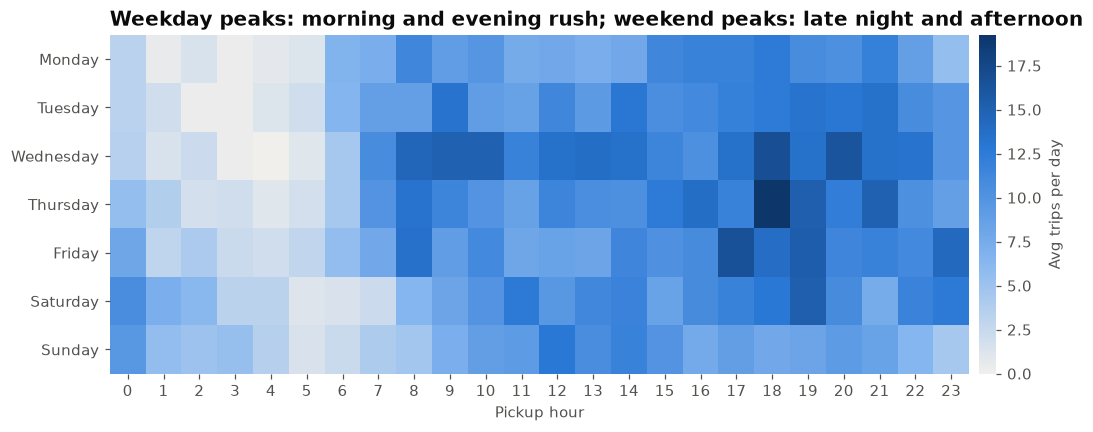

Top 5 peak slots (avg trips per occurrence):
pickup_day  pickup_hour
Thursday    18             19.2
Wednesday   18             16.8
Friday      17             16.6
Wednesday   20             16.2
Friday      19             15.4


In [19]:
# ==========================================
# 11. DAY x HOUR HEATMAP
# ==========================================

heat = (march.groupby(["pickup_day", "pickup_hour"], observed=True).size()
        .unstack(fill_value=0)
        .div(calendar.reindex(by_day.index).values, axis=0))   # trips per calendar day

fig, ax = plt.subplots(figsize=(12, 4))
from matplotlib.colors import LinearSegmentedColormap
seq = LinearSegmentedColormap.from_list("blues", ["#f0efec", "#86b6ef", "#2a78d6", "#0d366b"])
im = ax.imshow(heat, aspect="auto", cmap=seq)

ax.set_xticks(range(24), range(24))
ax.set_yticks(range(len(heat.index)), heat.index)
ax.set_xlabel("Pickup hour")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cbar = fig.colorbar(im, ax=ax, pad=0.01)
cbar.set_label("Avg trips per day", color=MUTED)
cbar.outline.set_visible(False)

ax.set_title("Weekday peaks: morning and evening rush; weekend peaks: late night and afternoon")
save_fig(fig, "08_demand_heatmap")
plt.show()

top_slots = heat.stack().sort_values(ascending=False).head(5).round(1)
print("Top 5 peak slots (avg trips per occurrence):")
print(top_slots.to_string())

## 2.4 Weekdays vs weekends

In [20]:
# ==========================================
# 12. WEEKDAY VS WEEKEND
# ==========================================

day_type = march["is_weekend"].map({False: "Weekday", True: "Weekend"})
n_days = {"Weekday": 21, "Weekend": 10}   # March 2019

weekend_summary = march.groupby(day_type).agg(
    trips=("total", "size"),
    avg_revenue=("total", "mean"),
    avg_distance=("distance", "mean"),
    avg_duration_min=("duration_min", "mean"),
    median_speed_mph=("speed_mph", "median"),
)
weekend_summary["trips_per_day"] = weekend_summary["trips"] / weekend_summary.index.map(n_days)
weekend_summary.round(2)

,trips,avg_revenue,avg_distance,avg_duration_min,median_speed_mph,trips_per_day
is_weekend,,,,,,
Weekday,4475,18.86,3.08,15.01,9.65,213.1
Weekend,1895,17.50,2.98,13.20,11.05,189.5


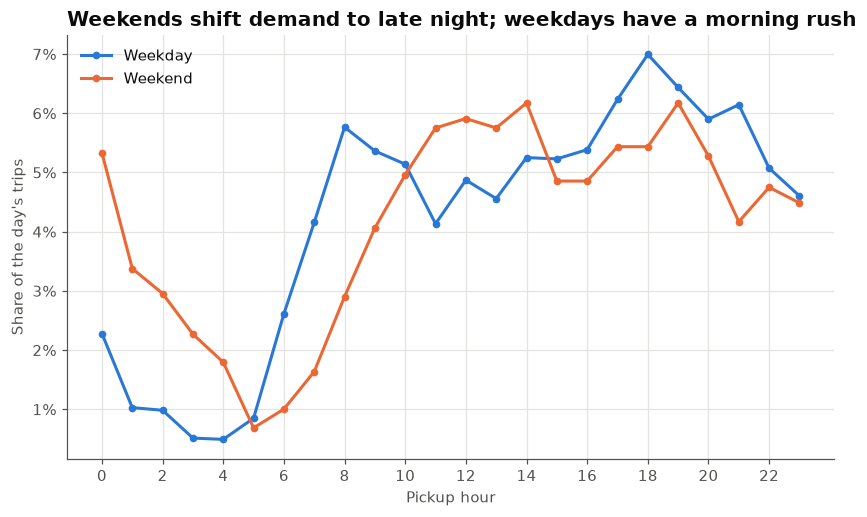

In [21]:
# Hourly profile as % of that day-type's trips (so both curves are comparable)
profile = march.groupby([day_type, "pickup_hour"]).size().unstack(0)
profile = profile / profile.sum() * 100

fig, ax = plt.subplots()
ax.plot(profile.index, profile["Weekday"], color=BLUE, linewidth=2, marker="o", markersize=4)
ax.plot(profile.index, profile["Weekend"], color=ORANGE, linewidth=2, marker="o", markersize=4)

ax.set_title("Weekends shift demand to late night; weekdays have a morning rush")
ax.set_xlabel("Pickup hour")
ax.set_ylabel("Share of the day's trips")
ax.set_xticks(range(0, 24, 2))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(["Weekday", "Weekend"], frameon=False, loc="upper left")

save_fig(fig, "09_weekday_vs_weekend")
plt.show()

**Insight: yes, the two follow clearly different patterns.**
- **Volume:** weekdays average **~213 trips/day** vs **~190 on weekends** (−11%).
- **Timing:**
  - Weekdays have a **morning rush (8–10 am)** and a bigger **evening peak at 6 pm** (7% of daily trips). This is a commuting pattern.
  - Weekends have **no morning rush**. Demand builds from late morning, stays steady through the afternoon, and is **2–5× higher after midnight**: midnight is 5.3% of weekend trips vs 2.3% on weekdays. This is a nightlife pattern.
- **Trip value:** weekend trips are slightly cheaper (**$17.50 vs $18.86**) and shorter (13.2 vs 15.0 min). Traffic is lighter on weekends, with a median speed of 11.1 vs 9.7 mph.

**Peak demand periods:** weekday evenings from 5 to 9 pm (strongest Wed–Fri), weekday mornings from 8 to 10 am, and weekend nights from midnight to 2 am.

## Part 2 — Summary: when customers need taxis

| Question | Answer |
|---|---|
| Busiest hour | **6 pm** (416 trips); 5–9 pm is the main peak |
| Highest-revenue hours | **6 pm, 5 pm, 7 pm** ($7.2k–$7.5k each) |
| Are busy hours the most profitable? | **In total revenue, yes; per trip, no.** The highest average trip value is at **4–5 am** (~$22–24, long/airport trips). Volume and value per trip are slightly negatively related (r = −0.31). |
| Low-demand periods | **1–6 am** (lowest at 5 am), plus Sundays and Mondays |
| Weekdays vs weekends | Weekdays: more trips, a commuter pattern (morning and evening rush), slower traffic. Weekends: ~11% fewer trips, a late-night peak, slightly cheaper and faster trips. |

**Business takeaway:** put the most cabs on the road on **weekday evenings (Wed–Fri, 5–9 pm)** and on **weekend nights**. The early morning has low volume, but those trips are valuable (airport runs), so some coverage is worth keeping.

---
# Part 3 — How do customers pay, and how much do they tip?

**Important caveat:** tips are only recorded for **credit card** payments. Cash tips are given directly to the driver and appear as **$0** in the data. Comparing tips between cash and card therefore compares *recorded* tips, not actual generosity. Tip analysis below uses **card trips only**.
`tip_pct` = tip ÷ fare × 100 (created in `02_data_cleaning`). Fare excludes surcharges, so this percentage runs a little higher than "tip ÷ total".

## 3.1 Cash vs credit card usage, tips and trip value

In [22]:
# ==========================================
# 13. PAYMENT METHODS
# ==========================================

by_payment = df.groupby("payment", observed=True).agg(
    trips=("total", "size"),
    avg_total=("total", "mean"),
    median_total=("total", "median"),
    avg_fare=("fare", "mean"),
    avg_tip=("tip", "mean"),
    avg_distance=("distance", "mean"),
).sort_values("trips", ascending=False)
by_payment["share_%"] = by_payment["trips"] / by_payment["trips"].sum() * 100
by_payment.round(2)

,trips,avg_total,median_total,avg_fare,avg_tip,avg_distance,share_%
payment,,,,,,,
credit card,4549,19.93,15.35,13.56,2.76,3.24,71.40
cash,1788,14.74,11.80,11.64,0.00,2.57,28.06
unknown,34,15.54,12.05,12.22,0.00,2.61,0.53


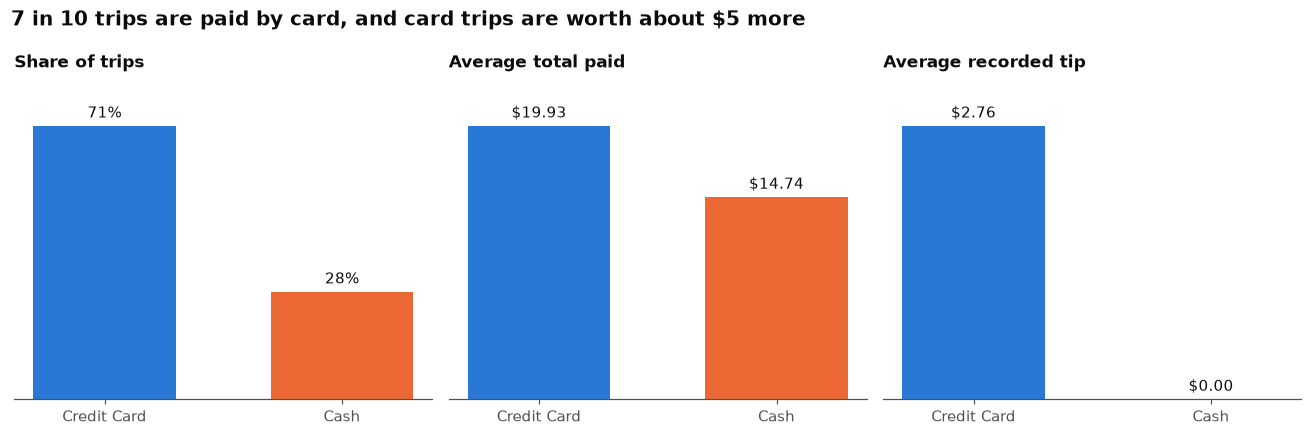

In [23]:
main = by_payment.loc[["credit card", "cash"]]
pay_colors = [BLUE, ORANGE]

panels = [
    ("share_%", "Share of trips", "{:.0f}%"),
    ("avg_total", "Average total paid", "${:.2f}"),
    ("avg_tip", "Average recorded tip", "${:.2f}"),
]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (col, title, fmt) in zip(axes, panels):
    bars = ax.bar(main.index.str.title(), main[col], color=pay_colors, width=0.6)
    ax.bar_label(bars, labels=[fmt.format(v) for v in main[col]], padding=3, color=TEXT)
    ax.set_title(title, fontsize=11)
    ax.set_ylim(0, main[col].max() * 1.18)
    ax.yaxis.set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.grid(False)

fig.suptitle("7 in 10 trips are paid by card, and card trips are worth about $5 more",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save_fig(fig, "10_payment_methods")
plt.show()

**Insight:**
- **Credit card is by far the most common: 71.4% of trips** (cash 28.1%, unknown 0.5%).
- **Card trips are worth more: $19.93 vs $14.74 on average** (+35%). The gap comes from three things:
  - **tips**: $2.76 recorded on card vs $0 on cash
  - **longer trips**: card trips average 3.24 mi vs 2.57 mi for cash
  - **a higher fare**: $13.56 vs $11.64
- Even **without tips**, card trips bring in ~$2.40 more each. Customers paying by card take longer, more expensive trips.
- Do card customers tip more? The data **can't fully answer** this, because cash tips aren't recorded. What it does show is that card trips generate **all** of the recorded tip revenue.

## 3.2 Tip percentage distribution (card trips)

In [24]:
# ==========================================
# 14. TIP PERCENTAGE
# ==========================================

card = df[df["payment"] == "credit card"].copy()

print(card["tip_pct"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1))
print(f"\nCard trips with no tip: {(card['tip'] == 0).mean():.1%}")

tip_bands = pd.cut(card["tip_pct"], [-0.1, 0, 10, 15, 20, 25, 30, np.inf],
                   labels=["0%", "0–10%", "10–15%", "15–20%", "20–25%", "25–30%", "30%+"])
tip_bands.value_counts(normalize=True).sort_index().mul(100).round(1).rename("share_%")

count    4549.0
mean       23.9
std        11.6
min         0.0
10%         2.6
25%        18.2
50%        25.6
75%        30.7
90%        35.6
max        93.3
Name: tip_pct, dtype: float64

Card trips with no tip: 9.7%


tip_pct
0%         9.7
0–10%      3.7
10–15%     6.5
15–20%     8.2
20–25%    18.5
25–30%    26.1
30%+      27.3
Name: share_%, dtype: float64

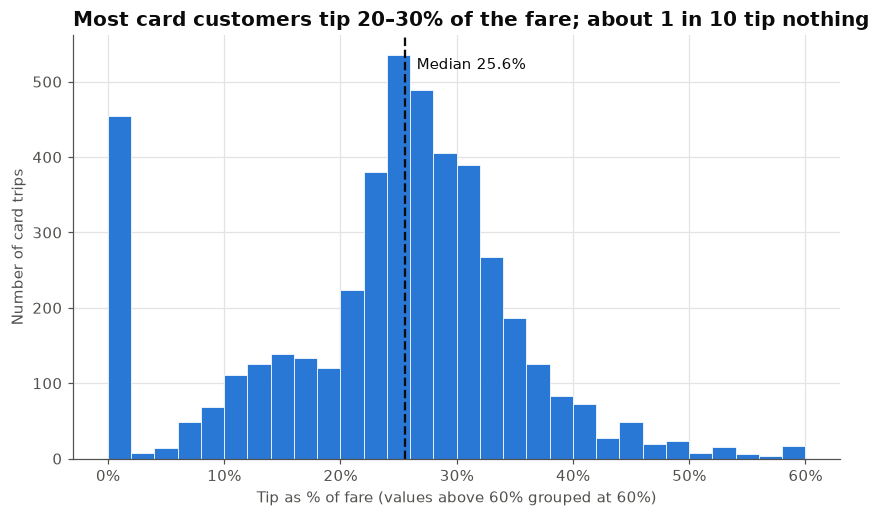

In [25]:
fig, ax = plt.subplots()
ax.hist(card["tip_pct"].clip(upper=60), bins=np.arange(0, 62, 2), color=BLUE, edgecolor="white", linewidth=0.5)
med_tip = card["tip_pct"].median()
ax.axvline(med_tip, color=TEXT, linestyle="--", linewidth=1.5)
ax.text(med_tip + 1, ax.get_ylim()[1] * 0.92, f"Median {med_tip:.1f}%", color=TEXT)

ax.set_title("Most card customers tip 20–30% of the fare; about 1 in 10 tip nothing")
ax.set_xlabel("Tip as % of fare (values above 60% grouped at 60%)")
ax.set_ylabel("Number of card trips")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))

save_fig(fig, "11_tip_distribution")
plt.show()

**Insight:**
- **Median tip is 25.6% of the fare** (mean 23.9%). Half of card customers tip between **18% and 31%**.
- **9.7% of card trips have no tip.** That shows up as a separate spike at 0%.
- The clusters around 20–30% match the **preset tip buttons** (20% / 25% / 30%) on the taxi payment screens. These defaults strongly shape tipping behaviour.

## 3.3 Does trip distance influence tipping?

In [26]:
# ==========================================
# 15. TIPS BY DISTANCE
# ==========================================

tips_by_distance = card.groupby("distance_band", observed=True).agg(
    trips=("tip", "size"),
    avg_tip=("tip", "mean"),
    median_tip_pct=("tip_pct", "median"),
)
print(f"Correlation distance vs tip ($): {card['distance'].corr(card['tip']):.2f}")
print(f"Correlation distance vs tip (%): {card['distance'].corr(card['tip_pct'], method='spearman'):.2f} (Spearman)")
tips_by_distance.round(2)

Correlation distance vs tip ($): 0.59
Correlation distance vs tip (%): -0.45 (Spearman)


,trips,avg_tip,median_tip_pct
distance_band,,,
Under 2 mi,2566,1.92,28.67
2–5 mi,1222,2.91,24.55
5–10 mi,436,4.25,22.25
10+ mi,325,6.88,20.48


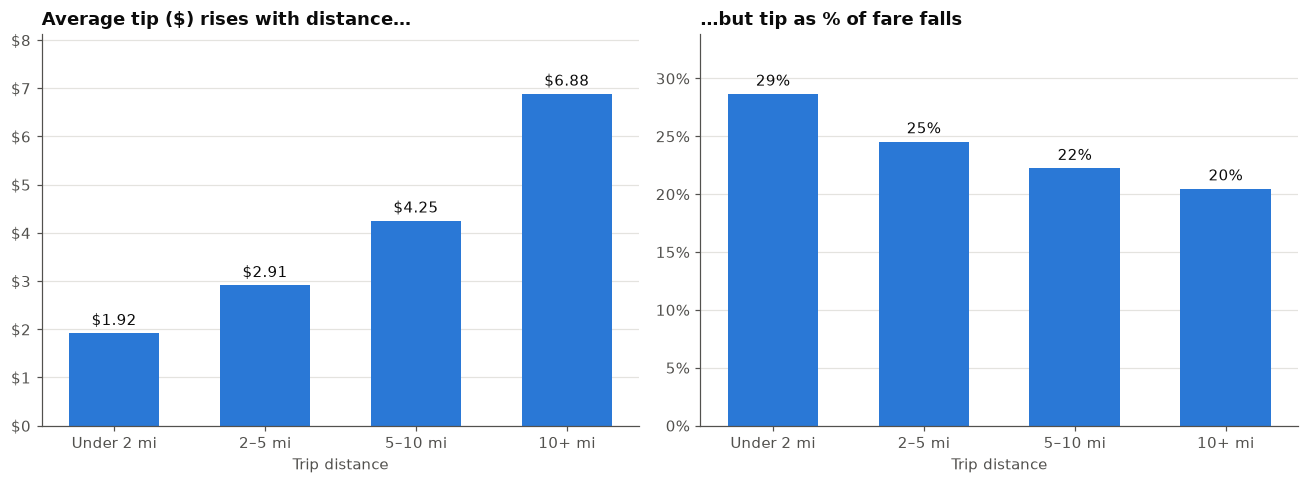

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (col, title, fmt, yfmt) in zip(axes, [
    ("avg_tip", "Average tip ($) rises with distance…", "${:.2f}", usd),
    ("median_tip_pct", "…but tip as % of fare falls", "{:.0f}%", mtick.PercentFormatter(decimals=0)),
]):
    bars = ax.bar(tips_by_distance.index, tips_by_distance[col], color=BLUE, width=0.6)
    ax.bar_label(bars, labels=[fmt.format(v) for v in tips_by_distance[col]], padding=3, color=TEXT)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Trip distance")
    ax.set_ylim(0, tips_by_distance[col].max() * 1.18)
    ax.yaxis.set_major_formatter(yfmt)
    ax.grid(axis="x", visible=False)

fig.tight_layout()
save_fig(fig, "12_tips_by_distance")
plt.show()

**Insight: yes, but in two opposite ways.**
- **Tip in dollars rises with distance**, from **$1.92** on trips under 2 mi to **$6.88** on 10+ mi trips (r = 0.59).
- **Tip as a percentage falls with distance**, from a **28.7%** median on short trips to **20.5%** on long trips.
- On short trips, customers often round up or press a preset button, which is a large percentage of a small fare. On long trips, they tip more money but a smaller share of the bill.

## Part 3 — Summary: how customers pay and tip

| Question | Answer |
|---|---|
| Most common payment method | **Credit card: 71%** of trips (cash 28%) |
| Do card customers tip more? | Card trips carry **all recorded tips (avg $2.76, median 25.6% of fare)**; cash tips aren't recorded, so a fair comparison isn't possible with this data |
| Does distance influence tipping? | **Yes.** Tip $ rises with distance ($1.92 → $6.88); tip % falls (29% → 20%) |
| Trip value by payment method | **Card $19.93 vs cash $14.74.** Card trips are longer and have higher fares even before tips |

**Business takeaway:** card payments bring in more per trip and give visibility into tips. Encouraging card payment (and keeping the 20–30% preset tip options) supports both revenue and driver earnings.

---
# Part 4 — Where are the most valuable taxi trips originating and ending?

## 4.1 Trips and revenue by borough

In [28]:
# ==========================================
# 16. BOROUGHS
# ==========================================

pickup_boro = df.groupby("pickup_borough", observed=True).agg(
    trips=("total", "size"),
    revenue=("total", "sum"),
    avg_revenue=("total", "mean"),
)
pickup_boro["trip_share_%"] = pickup_boro["trips"] / pickup_boro["trips"].sum() * 100
pickup_boro["revenue_share_%"] = pickup_boro["revenue"] / pickup_boro["revenue"].sum() * 100
pickup_boro = pickup_boro.sort_values("trips", ascending=False)

dropoff_boro = df.groupby("dropoff_borough", observed=True).agg(
    trips=("total", "size"),
    avg_revenue=("total", "mean"),
).sort_values("trips", ascending=False)

print("PICKUP BOROUGH")
display(pickup_boro.round(2))
print("DROP-OFF BOROUGH")
display(dropoff_boro.round(2))

PICKUP BOROUGH


,trips,revenue,avg_revenue,trip_share_%,revenue_share_%
pickup_borough,,,,,
Manhattan,5248,87396.19,16.65,82.37,74.35
Queens,637,20467.36,32.13,10.00,17.41
Brooklyn,374,7188.17,19.22,5.87,6.11
Bronx,97,2178.46,22.46,1.52,1.85
Unknown,15,324.42,21.63,0.24,0.28


DROP-OFF BOROUGH


,trips,avg_revenue
dropoff_borough,,
Manhattan,5186,16.78
Queens,524,26.47
Brooklyn,494,23.28
Bronx,136,25.23
Unknown,29,53.74
Staten Island,2,76.86


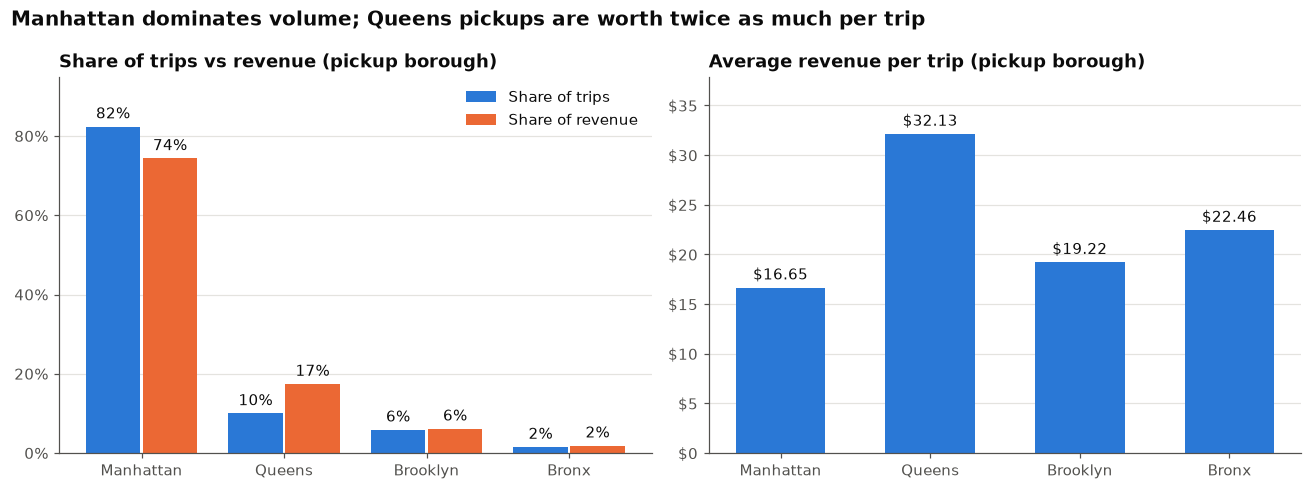

In [29]:
boro = pickup_boro.drop("Unknown", errors="ignore")
x = np.arange(len(boro))
w = 0.38

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

b1 = axes[0].bar(x - w / 2 - 0.01, boro["trip_share_%"], w, color=BLUE, label="Share of trips")
b2 = axes[0].bar(x + w / 2 + 0.01, boro["revenue_share_%"], w, color=ORANGE, label="Share of revenue")
axes[0].bar_label(b1, fmt="%.0f%%", padding=3, color=TEXT)
axes[0].bar_label(b2, fmt="%.0f%%", padding=3, color=TEXT)
axes[0].set_xticks(x, boro.index)
axes[0].set_title("Share of trips vs revenue (pickup borough)", fontsize=12)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[0].set_ylim(0, 95)
axes[0].legend(frameon=False)

bars = axes[1].bar(boro.index, boro["avg_revenue"], color=BLUE, width=0.6)
axes[1].bar_label(bars, fmt="$%.2f", padding=3, color=TEXT)
axes[1].set_title("Average revenue per trip (pickup borough)", fontsize=12)
axes[1].yaxis.set_major_formatter(usd)
axes[1].set_ylim(0, boro["avg_revenue"].max() * 1.18)

for ax in axes:
    ax.grid(axis="x", visible=False)
fig.suptitle("Manhattan dominates volume; Queens pickups are worth twice as much per trip",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save_fig(fig, "13_boroughs")
plt.show()

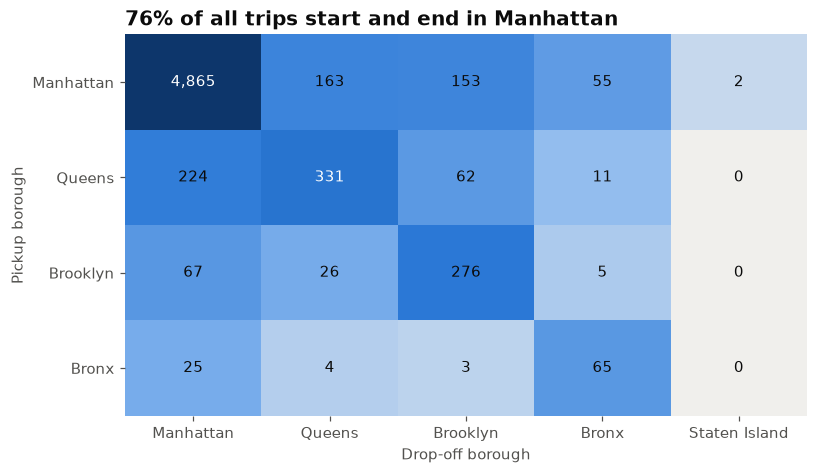

Manhattan → Manhattan: 76.4% of trips


In [30]:
# Pickup -> drop-off borough flows
flows = pd.crosstab(df["pickup_borough"], df["dropoff_borough"])
flows = flows.loc[boro.index, [c for c in ["Manhattan", "Queens", "Brooklyn", "Bronx", "Staten Island"] if c in flows.columns]]

fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(np.log10(flows + 1), cmap=seq, aspect="auto")
for i in range(flows.shape[0]):
    for j in range(flows.shape[1]):
        v = flows.iat[i, j]
        ax.text(j, i, f"{v:,}", ha="center", va="center",
                color="white" if v > 300 else TEXT, fontsize=10)
ax.set_xticks(range(flows.shape[1]), flows.columns)
ax.set_yticks(range(flows.shape[0]), flows.index)
ax.set_xlabel("Drop-off borough")
ax.set_ylabel("Pickup borough")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("76% of all trips start and end in Manhattan")

save_fig(fig, "14_borough_flows")
plt.show()

print(f"Manhattan → Manhattan: {flows.loc['Manhattan', 'Manhattan'] / len(df):.1%} of trips")

**Insight:**
- **Manhattan generates the most trips: 5,248 pickups (82%)** and **74% of revenue**. **76% of all trips start and end in Manhattan.**
- **Queens punches above its weight:** 10% of trips but **17% of revenue**, with an average trip worth **$32.13**, about **2× a Manhattan trip ($16.65)**. Queens contains both airports.
- Drop-offs follow the same pattern. Trips **ending** outside Manhattan are worth much more (Queens $26.47, Bronx $25.23, Brooklyn $23.28 vs Manhattan $16.78), because they are longer.
- Staten Island is almost absent (2 drop-offs, 0 pickups).

## 4.2 Top pickup and drop-off zones

In [31]:
# ==========================================
# 17. ZONES
# ==========================================

by_zone = (df[df["pickup_zone"] != "Unknown"]
           .groupby("pickup_zone", observed=True)
           .agg(trips=("total", "size"), revenue=("total", "sum"),
                avg_revenue=("total", "mean"), avg_distance=("distance", "mean"))
           .sort_values("revenue", ascending=False))
by_zone["revenue_share_%"] = by_zone["revenue"] / df["total"].sum() * 100

print(f"Top 10 pickup zones generate {by_zone['revenue'].head(10).sum() / df['total'].sum():.1%} of revenue "
      f"(out of {len(by_zone)} zones)")
print("\nTOP 10 PICKUP ZONES BY REVENUE")
display(by_zone.head(10).round(2))

print("TOP 10 PICKUP ZONES BY TRIPS")
display(by_zone.sort_values("trips", ascending=False).head(10).round(2))

print("TOP 10 DROP-OFF ZONES BY TRIPS")
display(df[df["dropoff_zone"] != "Unknown"].groupby("dropoff_zone", observed=True)
        .agg(trips=("total", "size"), avg_revenue=("total", "mean"))
        .sort_values("trips", ascending=False).head(10).round(2))

Top 10 pickup zones generate 35.2% of revenue (out of 192 zones)

TOP 10 PICKUP ZONES BY REVENUE


,trips,revenue,avg_revenue,avg_distance,revenue_share_%
pickup_zone,,,,,
JFK Airport,145,8183.72,56.44,15.64,6.96
LaGuardia Airport,146,6268.36,42.93,9.27,5.33
Midtown Center,229,4179.32,18.25,2.61,3.56
Penn Station/Madison Sq West,210,3652.63,17.39,2.20,3.11
Times Sq/Theatre District,183,3421.30,18.70,2.71,2.91
Midtown East,198,3400.49,17.17,2.24,2.89
Clinton East,207,3231.10,15.61,2.08,2.75
Union Sq,180,3068.70,17.05,2.20,2.61
Lincoln Square East,176,2972.59,16.89,2.39,2.53


TOP 10 PICKUP ZONES BY TRIPS


,trips,revenue,avg_revenue,avg_distance,revenue_share_%
pickup_zone,,,,,
Midtown Center,229,4179.32,18.25,2.61,3.56
Upper East Side South,211,2963.19,14.04,1.63,2.52
Penn Station/Madison Sq West,210,3652.63,17.39,2.20,3.11
Clinton East,207,3231.10,15.61,2.08,2.75
Midtown East,198,3400.49,17.17,2.24,2.89
Upper East Side North,186,2670.64,14.36,1.70,2.27
Times Sq/Theatre District,183,3421.30,18.70,2.71,2.91
Union Sq,180,3068.70,17.05,2.20,2.61
Lincoln Square East,176,2972.59,16.89,2.39,2.53


TOP 10 DROP-OFF ZONES BY TRIPS


,trips,avg_revenue
dropoff_zone,,
Upper East Side North,245,15.54
Murray Hill,218,15.95
Midtown Center,214,17.66
Upper East Side South,176,15.86
Midtown East,176,17.39
Times Sq/Theatre District,159,16.95
Lincoln Square East,155,16.07
Clinton East,150,17.39
East Village,150,17.25


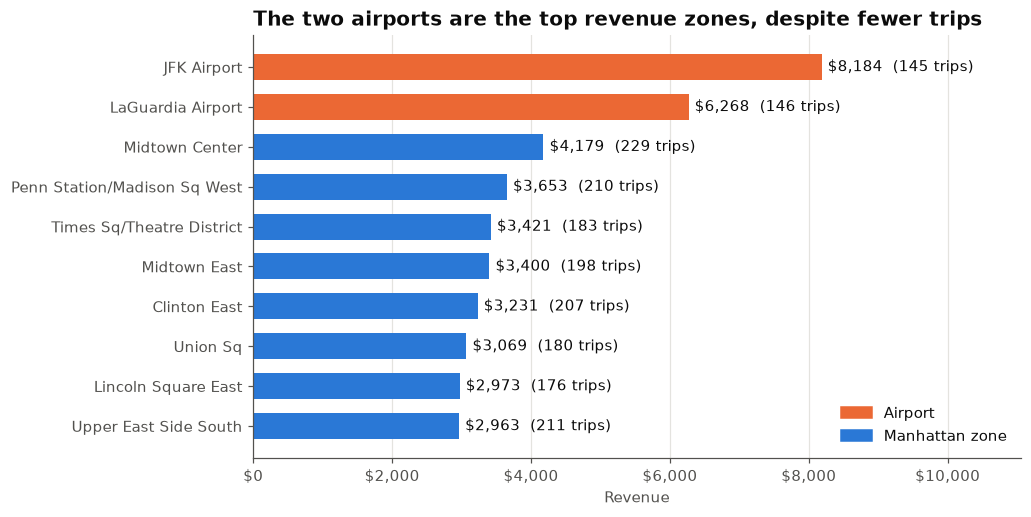

In [32]:
top = by_zone.head(10).iloc[::-1]
is_airport_zone = top.index.str.contains("Airport")

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top.index, top["revenue"], color=[ORANGE if a else BLUE for a in is_airport_zone], height=0.65)
ax.bar_label(bars, labels=[f"${r:,.0f}  ({n} trips)" for r, n in zip(top["revenue"], top["trips"])],
             padding=4, color=TEXT)
ax.set_xlim(0, top["revenue"].max() * 1.35)
ax.xaxis.set_major_formatter(usd)
ax.set_xlabel("Revenue")
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
          labels=["Airport", "Manhattan zone"], frameon=False, loc="lower right")
ax.set_title("The two airports are the top revenue zones, despite fewer trips")

save_fig(fig, "15_top_pickup_zones")
plt.show()

## 4.3 Are the busiest pickup zones also the most profitable?

63 zones with 20+ pickups — Spearman (trips vs avg revenue): 0.16


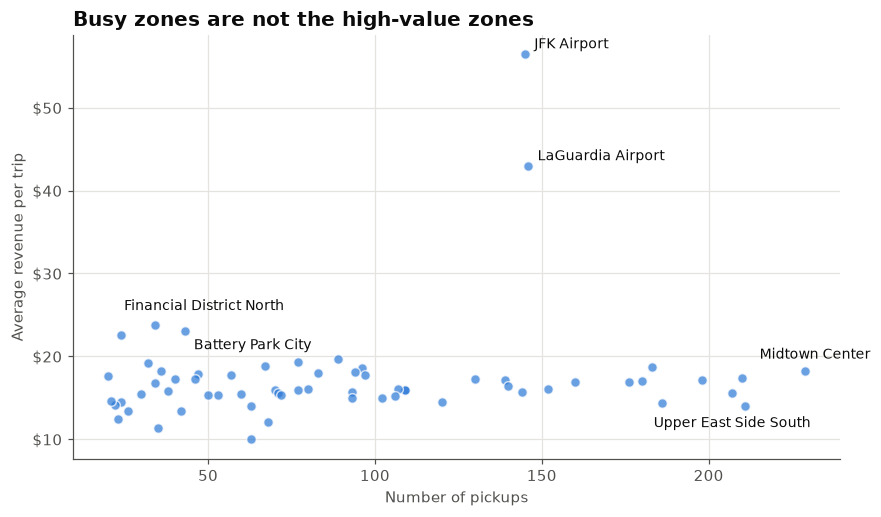


HIGHEST AVERAGE TRIP VALUE (zones with 20+ pickups)


,trips,revenue,avg_revenue,avg_distance,revenue_share_%
pickup_zone,,,,,
JFK Airport,145,8183.72,56.44,15.64,6.96
LaGuardia Airport,146,6268.36,42.93,9.27,5.33
Financial District North,34,807.31,23.74,4.58,0.69
Battery Park City,43,992.24,23.08,4.05,0.84
World Trade Center,24,542.13,22.59,4.59,0.46
TriBeCa/Civic Center,89,1748.15,19.64,2.88,1.49
Lower East Side,77,1486.52,19.31,3.20,1.26
Washington Heights South,32,615.83,19.24,3.69,0.52
UN/Turtle Bay South,67,1264.16,18.87,2.76,1.08


In [33]:
# Zones with at least 20 pickups (smaller zones give unreliable averages)
zones20 = by_zone[by_zone["trips"] >= 20]
rho = zones20["trips"].corr(zones20["avg_revenue"], method="spearman")
print(f"{len(zones20)} zones with 20+ pickups — Spearman (trips vs avg revenue): {rho:.2f}")

fig, ax = plt.subplots()
ax.scatter(zones20["trips"], zones20["avg_revenue"], s=40, color=BLUE, alpha=0.7,
           edgecolors="white", linewidths=1)
label_offsets = {"JFK Airport": (6, 4), "LaGuardia Airport": (6, 4), "Midtown Center": (-30, 8),
                 "Upper East Side South": (-60, -14), "Financial District North": (-20, 10),
                 "Battery Park City": (6, -12)}
for zone, offset in label_offsets.items():
    if zone in zones20.index:
        ax.annotate(zone, (zones20.loc[zone, "trips"], zones20.loc[zone, "avg_revenue"]),
                    xytext=offset, textcoords="offset points", fontsize=9, color=TEXT)

ax.set_title("Busy zones are not the high-value zones")
ax.set_xlabel("Number of pickups")
ax.set_ylabel("Average revenue per trip")
ax.yaxis.set_major_formatter(usd)

save_fig(fig, "16_zone_volume_vs_value")
plt.show()

print("\nHIGHEST AVERAGE TRIP VALUE (zones with 20+ pickups)")
zones20.sort_values("avg_revenue", ascending=False).head(10).round(2)

## 4.4 Popular pickup → drop-off combinations

In [34]:
# ==========================================
# 18. ROUTES
# ==========================================

known = df[(df["pickup_zone"] != "Unknown") & (df["dropoff_zone"] != "Unknown")]
routes = (known.groupby(["pickup_zone", "dropoff_zone"], observed=True)
          .agg(trips=("total", "size"), avg_revenue=("total", "mean"), avg_distance=("distance", "mean"))
          .sort_values("trips", ascending=False))

print("MOST POPULAR ROUTES")
display(routes.head(10).round(2))

print("HIGHEST-REVENUE ROUTES")
routes["revenue"] = routes["trips"] * routes["avg_revenue"]
routes.sort_values("revenue", ascending=False).head(10).round(2)

MOST POPULAR ROUTES


,,trips,avg_revenue,avg_distance
pickup_zone,dropoff_zone,,,
Upper East Side North,Upper East Side North,38,9.30,0.57
Upper East Side South,Upper East Side North,30,11.84,1.14
Upper East Side North,Upper East Side South,23,11.83,0.98
Astoria,Astoria,22,7.16,0.82
Central Harlem,Central Harlem North,20,8.33,1.16
Union Sq,Murray Hill,19,12.86,1.12
Upper West Side South,Lincoln Square East,19,11.15,0.98
Upper East Side South,Lenox Hill East,18,11.14,0.90
Upper East Side North,Midtown East,17,15.54,1.76


HIGHEST-REVENUE ROUTES


,,trips,avg_revenue,avg_distance,revenue
pickup_zone,dropoff_zone,,,,
LaGuardia Airport,Midtown Center,10,50.26,10.12,502.59
JFK Airport,Midtown Center,5,73.13,17.68,365.64
Upper East Side South,Upper East Side North,30,11.84,1.14,355.22
Upper East Side North,Upper East Side North,38,9.30,0.57,353.22
LaGuardia Airport,Midtown East,8,42.24,9.23,337.94
Times Sq/Theatre District,LaGuardia Airport,6,53.82,10.80,322.92
JFK Airport,Midtown North,5,64.06,18.16,320.28
Midtown North,LaGuardia Airport,6,50.99,10.47,305.95
JFK Airport,Penn Station/Madison Sq West,4,71.34,17.60,285.35


**Insight:**
- **Highest-revenue pickup zones:** **JFK Airport ($8,184)** and **LaGuardia Airport ($6,268)**, followed by Midtown Center ($4,179), Penn Station ($3,653) and Times Square ($3,421). The **top 10 zones generate ~35% of all revenue**.
- **Busiest ≠ most profitable.** The busiest zone is **Midtown Center (229 pickups)**, but JFK earns **2× more revenue with fewer pickups (145)**. Among zones with 20+ pickups, the number of pickups and the average trip value are barely related (Spearman ρ = 0.16).
- **High average trip value:**
  - **JFK ($56.44)** and **LaGuardia ($42.93)**, far ahead of everything else
  - then **Lower Manhattan / Downtown** (Financial District North $23.74, Battery Park City $23.08, World Trade Center $22.59), where trips tend to go uptown or to Brooklyn
- **Highest-revenue routes are airport ↔ Midtown**: LaGuardia → Midtown Center (10 trips, $50 each), JFK → Midtown Center ($73 each), Times Square → LaGuardia ($54 each).
- **Most popular routes are short and cheap:** Upper East Side North → Upper East Side North (38 trips, $9.30 each), and trips between UES North and UES South (~$11.80). These are the volume base, not the value.

## Part 4 — Summary: where valuable trips start and end

| Question | Answer |
|---|---|
| Borough with most trips | **Manhattan**: 82% of pickups, 74% of revenue |
| Highest-revenue pickup zones | **JFK** ($8.2k) and **LaGuardia** ($6.3k), then Midtown Center, Penn Station, Times Square |
| Busiest zones = most profitable? | **No.** Busiest zones (Midtown, Upper East Side) have many short, cheap trips; airports have fewer, far more valuable trips (ρ = 0.16) |
| High average trip value | **JFK ($56)**, **LaGuardia ($43)**, Lower Manhattan (~$23); also trips that **end** outside Manhattan |

**Business takeaway:** Manhattan provides the steady volume, while **airport pickups are the most valuable locations**. Keeping cabs available at JFK/LaGuardia, and in Downtown at peak times, increases revenue per trip.

---
# Part 5 — How efficiently are taxi trips being completed?

## 5.1 Duration, distance, speed, revenue per mile and per minute

In [35]:
# ==========================================
# 19. EFFICIENCY METRICS
# ==========================================

df["revenue_per_mile"] = df["total"] / df["distance"]
df["revenue_per_min"] = df["total"] / df["duration_min"]

efficiency_cols = ["duration_min", "distance", "speed_mph", "revenue_per_mile", "revenue_per_min"]
summary = df[efficiency_cols].agg(["mean", "median"]).T
summary.columns = ["average", "median"]
summary.round(2)

,average,median
duration_min,14.47,10.97
distance,3.05,1.66
speed_mph,11.49,10.07
revenue_per_mile,9.74,8.30
revenue_per_min,1.61,1.35


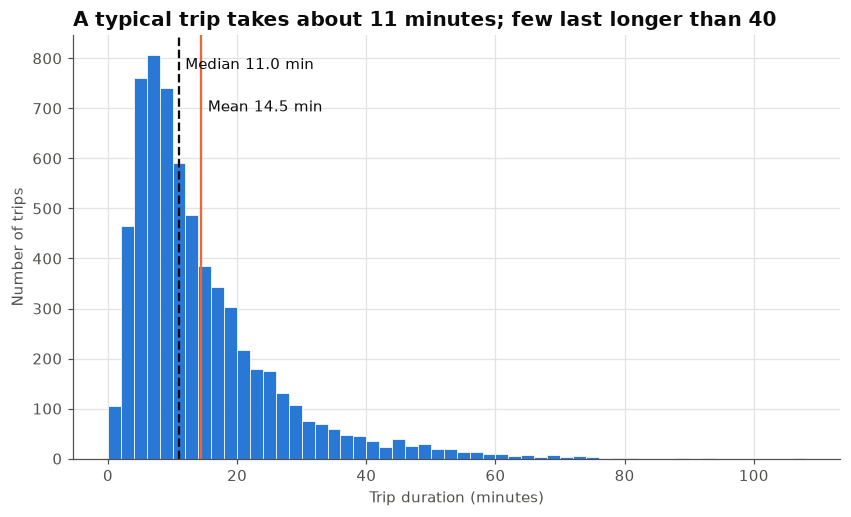

In [36]:
fig, ax = plt.subplots()
ax.hist(df["duration_min"], bins=np.arange(0, 110, 2), color=BLUE, edgecolor="white", linewidth=0.5)
for val, label, color, y in [(df["duration_min"].median(), "Median", TEXT, 0.92),
                             (df["duration_min"].mean(), "Mean", ORANGE, 0.82)]:
    ax.axvline(val, color=color, linewidth=1.5, linestyle="--" if label == "Median" else "-")
    ax.text(val + 1, ax.get_ylim()[1] * y, f"{label} {val:.1f} min", color=TEXT)

ax.set_title("A typical trip takes about 11 minutes; few last longer than 40")
ax.set_xlabel("Trip duration (minutes)")
ax.set_ylabel("Number of trips")

save_fig(fig, "17_duration_distribution")
plt.show()

**Insight:**
- **Average trip duration: 14.5 min** (median **11.0 min**)
- **Average distance: 3.05 mi** (median **1.66 mi**)
- **Average speed: 11.5 mph** (median **10.1 mph**). This is typical for NYC traffic.
- **Revenue per mile:** median **$8.30**. **Revenue per minute:** median **$1.35**, which works out to about **$81 per hour** of driving with a passenger.
- All of these are right-skewed: a few long trips pull the averages above the medians.

## 5.2 Which trips take unusually long?

In [37]:
# ==========================================
# 20. UNUSUALLY LONG TRIPS
# ==========================================

q1, q3 = df["duration_min"].quantile([0.25, 0.75])
long_fence = q3 + 1.5 * (q3 - q1)
long_trips = df[df["duration_min"] > long_fence]

print(f"Duration upper fence: {long_fence:.1f} min")
print(f"Trips above it: {len(long_trips)} ({len(long_trips) / len(df):.1%})")
print(f"  avg distance: {long_trips['distance'].mean():.1f} mi, "
      f"airport share: {is_airport[long_trips.index].mean():.0%}")

# Long in time but short in distance = stuck in traffic
stuck = df[(df["duration_min"] > 30) & (df["distance"] < 3)]
print(f"\nTrips > 30 min but < 3 mi (traffic): {len(stuck)}")
display(stuck.sort_values("speed_mph")[["pickup", "distance", "duration_min", "speed_mph", "total",
                                         "pickup_zone", "dropoff_zone"]].head(8).round(2))

print("LONGEST TRIPS")
df.nlargest(5, "duration_min")[["pickup", "distance", "duration_min", "speed_mph", "total",
                                "pickup_zone", "dropoff_zone"]].round(2)

Duration upper fence: 36.5 min
Trips above it: 359 (5.6%)
  avg distance: 13.2 mi, airport share: 44%

Trips > 30 min but < 3 mi (traffic): 15


/var/folders/76/qlp_kr813x7fbxq00qyd32nr0000gn/T/ipykernel_2246/2800516774.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "pickup_zone", "dropoff_zone"]].head(8).round(2))


,pickup,distance,duration_min,speed_mph,total,pickup_zone,dropoff_zone
2342,2019-03-21 08:13:04,1.50,40.62,2.22,15.00,Midtown East,Times Sq/Theatre District
3889,2019-03-08 10:28:37,1.35,34.63,2.34,23.30,Clinton East,UN/Turtle Bay South
4859,2019-03-05 09:39:15,2.20,42.87,3.08,27.80,West Chelsea/Hudson Yards,Midtown East
705,2019-03-21 17:39:50,1.74,33.07,3.16,25.56,Midtown East,Unknown
4867,2019-03-21 17:18:47,1.70,30.43,3.35,27.35,Flatiron,Clinton West
1090,2019-03-09 14:49:45,2.25,39.23,3.44,24.80,Penn Station/Madison Sq West,Union Sq
1297,2019-03-09 13:09:17,2.11,33.98,3.73,29.76,West Chelsea/Hudson Yards,TriBeCa/Civic Center
4008,2019-03-06 10:34:48,2.05,31.08,3.96,21.80,UN/Turtle Bay South,Garment District


LONGEST TRIPS


/var/folders/76/qlp_kr813x7fbxq00qyd32nr0000gn/T/ipykernel_2246/2800516774.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "pickup_zone", "dropoff_zone"]].round(2)


,pickup,distance,duration_min,speed_mph,total,pickup_zone,dropoff_zone
6005,2019-03-05 07:23:49,22.17,107.67,12.35,82.36,University Heights/Morris Heights,Yorkville East
5527,2019-03-07 00:28:57,25.51,93.97,16.29,94.80,Sunset Park West,Saint Albans
5606,2019-03-19 14:21:35,33.46,89.88,22.34,169.70,East Flushing,Unknown
5786,2019-03-06 17:12:17,12.79,88.55,8.67,58.80,Queensbridge/Ravenswood,Flatlands
4190,2019-03-29 17:32:20,26.92,81.53,19.81,100.49,JFK Airport,Cobble Hill


**Insight:**
- **359 trips (5.6%) take longer than 36.5 min**, the statistical outlier threshold. Most of them are **long-distance** trips (avg **13.2 mi**, **44% airport**), so the long duration is expected.
- **The real inefficiency is traffic:** **15 trips lasted 30+ min while covering under 3 mi**, at **2–4 mph**. Examples: Midtown East → Times Square, 1.5 mi in 41 min. They are mostly in **Midtown/Chelsea during the daytime**.
- The longest trip is **107.7 min** (22 mi, Bronx → Upper East Side, 7 am weekday rush).

## 5.3 Does a longer trip duration produce higher revenue?

Correlation duration vs total: 0.86
Correlation distance vs total: 0.94


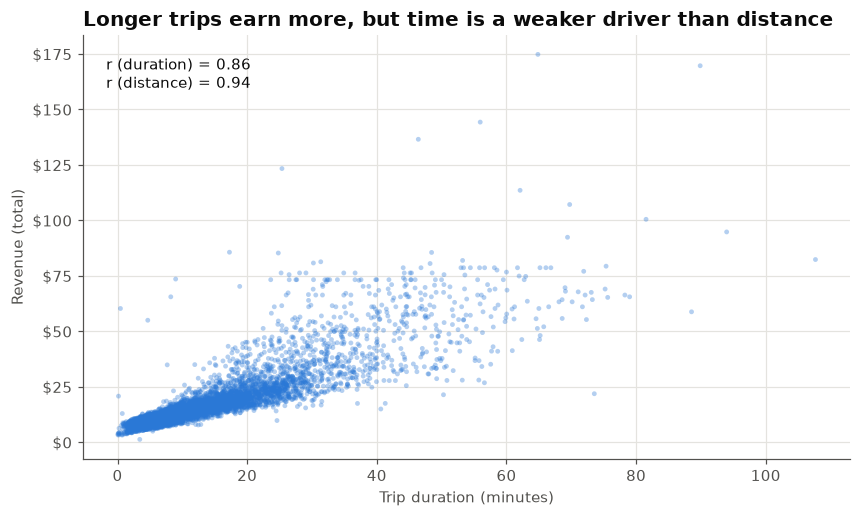

,revenue_per_mile,revenue_per_min,speed_mph
distance_band,,,
Under 2 mi,10.67,1.52,8.78
2–5 mi,6.32,1.14,10.96
5–10 mi,4.55,1.22,16.70
10+ mi,3.74,1.38,22.15


In [38]:
# ==========================================
# 21. DURATION VS REVENUE
# ==========================================

print(f"Correlation duration vs total: {df['duration_min'].corr(df['total']):.2f}")
print(f"Correlation distance vs total: {df['distance'].corr(df['total']):.2f}")

fig, ax = plt.subplots()
ax.scatter(df["duration_min"], df["total"], s=10, alpha=0.35, color=BLUE, edgecolors="none")
ax.set_title("Longer trips earn more, but time is a weaker driver than distance")
ax.set_xlabel("Trip duration (minutes)")
ax.set_ylabel("Revenue (total)")
ax.yaxis.set_major_formatter(usd)
ax.text(0.03, 0.95, f"r (duration) = {df['duration_min'].corr(df['total']):.2f}\n"
                    f"r (distance) = {df['distance'].corr(df['total']):.2f}",
        transform=ax.transAxes, va="top", color=TEXT)

save_fig(fig, "18_duration_vs_revenue")
plt.show()

df.groupby("distance_band", observed=True)[["revenue_per_mile", "revenue_per_min", "speed_mph"]].median().round(2)

**Insight: yes, but distance matters more than time.**
- Correlation with revenue: **duration r = 0.86** vs **distance r = 0.94**. The NYC meter charges mainly by distance, and only by time when the cab is slow or stopped.
- The scatter widens as duration grows: a 40-minute trip can earn $20 (stuck in traffic) or $70 (motorway to an airport).
- **Revenue per minute is lowest for 2–5 mi trips ($1.14/min)**. Very short trips earn more per minute ($1.52) because of the fixed starting charge, and long trips ($1.38) because they move fast (22 mph).

## 5.4 Which time periods have the highest average trip duration?

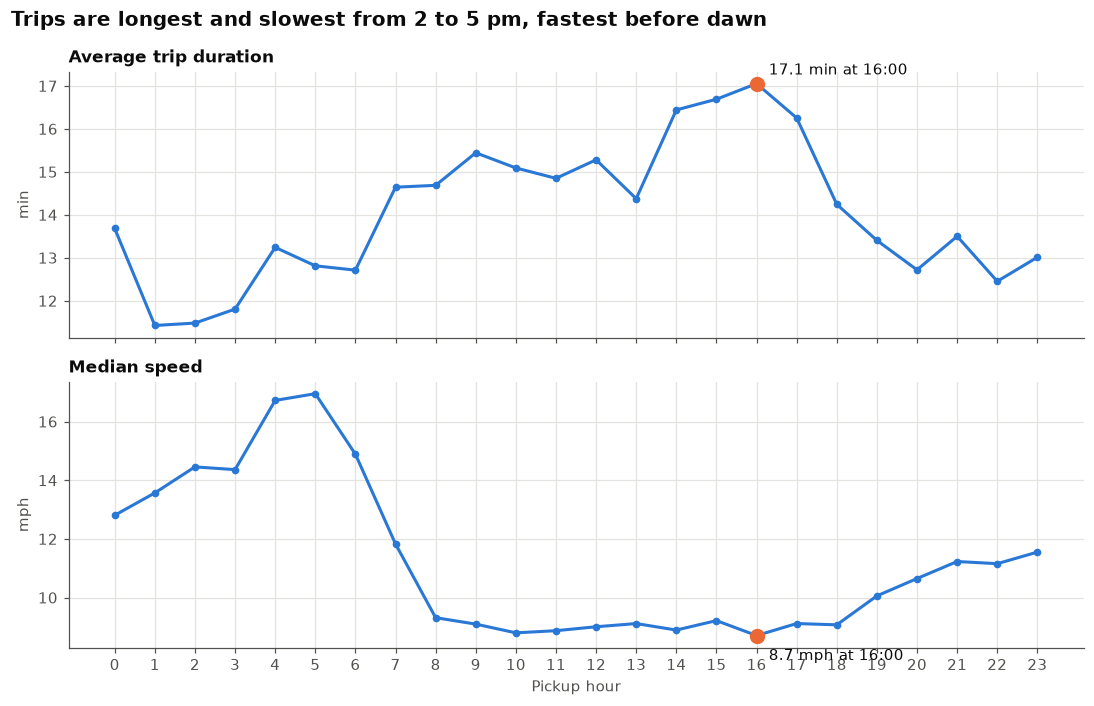

,avg_duration,median_speed,median_rev_per_min
pickup_hour,,,
0,13.68,12.81,1.47
1,11.42,13.57,1.61
2,11.48,14.46,1.55
3,11.81,14.36,1.55
4,13.24,16.72,1.84
5,12.81,16.95,1.87
6,12.71,14.89,1.69
7,14.64,11.83,1.43
8,14.69,9.31,1.29


In [39]:
# ==========================================
# 22. DURATION & SPEED BY HOUR
# ==========================================

eff_hour = df.groupby("pickup_hour").agg(
    avg_duration=("duration_min", "mean"),
    median_speed=("speed_mph", "median"),
    median_rev_per_min=("revenue_per_min", "median"),
)

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
for ax, (col, label, unit) in zip(axes, [("avg_duration", "Average trip duration", "min"),
                                         ("median_speed", "Median speed", "mph")]):
    ax.plot(eff_hour.index, eff_hour[col], color=BLUE, linewidth=2, marker="o", markersize=4)
    extreme = eff_hour[col].idxmax() if col == "avg_duration" else eff_hour[col].idxmin()
    ax.plot(extreme, eff_hour.loc[extreme, col], "o", color=ORANGE, markersize=9)
    ax.annotate(f"{eff_hour.loc[extreme, col]:.1f} {unit} at {extreme}:00", (extreme, eff_hour.loc[extreme, col]),
                xytext=(8, 6) if col == "avg_duration" else (8, -16), textcoords="offset points", color=TEXT)
    ax.set_title(label, fontsize=11)
    ax.set_ylabel(unit)

axes[-1].set_xticks(range(0, 24))
axes[-1].set_xlabel("Pickup hour")
fig.suptitle("Trips are longest and slowest from 2 to 5 pm, fastest before dawn",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save_fig(fig, "19_duration_speed_by_hour")
plt.show()

eff_hour.round(2)

**Insight:**
- **Longest average trips: 2–5 pm (16.4–17.1 min)**, peaking at **4 pm (17.1 min)**.
- Traffic is slowest **all working day long (8 am–6 pm), at about 9 mph**, down to **8.7 mph at 4 pm**.
- Trips are **fastest at 4–5 am (~17 mph)**, almost twice daytime speed. Even though those trips are longer in distance, they take *less* time than a daytime trip.
- In money terms: drivers earn **~$1.22–1.30 per minute** in the daytime slowdown vs **~$1.85 per minute** at 4–5 am.

## 5.5 Are some trips generating unusually low revenue per mile?

In [40]:
# ==========================================
# 23. LOW REVENUE PER MILE
# ==========================================

low_cut = df["revenue_per_mile"].quantile(0.01)
low_rpm = df[df["revenue_per_mile"] < low_cut]

print(f"Bottom 1% threshold: ${low_cut:.2f} per mile  ({len(low_rpm)} trips)")
print(f"  median distance: {low_rpm['distance'].median():.1f} mi")
print(f"  airport trips:   {is_airport[low_rpm.index].sum()}")
print(f"  $52 flat fares:  {(low_rpm['fare'] == 52).sum()}")
print(f"  paid in cash:    {(low_rpm['payment'] == 'cash').sum()}")

print(f"\nTrips under $2 per mile:")
df[df["revenue_per_mile"] < 2][["distance", "duration_min", "fare", "total", "revenue_per_mile",
                                "payment", "pickup_zone", "dropoff_zone"]].round(2)

Bottom 1% threshold: $3.05 per mile  (64 trips)
  median distance: 12.9 mi
  airport trips:   19
  $52 flat fares:  7
  paid in cash:    23

Trips under $2 per mile:


,distance,duration_min,fare,total,revenue_per_mile,payment,pickup_zone,dropoff_zone
1490,3.1,3.43,1.00,1.30,0.42,cash,Long Island City/Hunters Point,Long Island City/Hunters Point
6283,17.1,50.43,33.27,33.77,1.97,credit card,Queensboro Hill,Eastchester


**Insight:**
- **Revenue per mile naturally falls with distance:** median **$10.67/mile** for trips under 2 mi vs **$3.74/mile** for 10+ mi trips. Every trip pays a fixed starting charge plus surcharges, and on a short trip that fixed amount is spread over very few miles.
- The **bottom 1% (below $3.05/mile, 64 trips)** are almost all **long trips** (median 12.9 mi). That includes **19 airport trips** and **7 flat $52 JFK fares**, where the fare is capped no matter how far the cab drives. These are expected, not errors.
- **Only 2 trips earn under $2/mile:**
  - **$1.30 for 3.1 mi** (fare $1.00, cash): almost certainly a **data error** or an unrecorded fare
  - **$33.77 for 17.1 mi**: a long Queens → Bronx trip at a low metered rate, worth checking

**Efficiency takeaway:** the biggest efficiency loss isn't individual bad trips. It's **daytime Midtown traffic**, where average speeds of about 9 mph cut revenue per minute by about a third compared with off-peak hours.

## Part 5 — Summary: how efficiently trips are completed

| Question | Answer |
|---|---|
| Average trip duration | **14.5 min** (median 11.0 min); avg distance 3.05 mi; avg speed 11.5 mph |
| Unusually long trips | **359 trips > 36.5 min**, mostly long airport trips; **15 trips crawl at 2–4 mph** through Midtown in daytime traffic |
| Longer duration → higher revenue? | **Yes (r = 0.86)**, but distance is the stronger driver (r = 0.94) |
| Time periods with longest trips | **2–5 pm** (up to 17.1 min at 4 pm); slowest speeds 8 am–6 pm (~9 mph) |
| Unusually low revenue per mile | Mostly **long / flat-fare airport trips** (expected). Only **2 trips < $2/mile**, one clearly a data error |

**Business takeaway:** cabs earn the most per minute in **light traffic (late night / early morning)** and on short hops, and the least when **stuck in daytime Midtown traffic**. Pricing and dispatch decisions should take time-of-day congestion into account.